# 1. Project Setup

## 1.1 Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import f_oneway
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, learning_curve, cross_val_score, RepeatedKFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder,FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_regression
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.inspection import permutation_importance

## 1.2 Configuration

In [2]:
from sklearn import set_config
set_config(transform_output="pandas")

plt.style.use('seaborn-v0_8-whitegrid')

## 1.3 Random Seeds & Target

In [3]:
RANDOM_STATE = 42
TARGET = 'CO2 Emissions(g/km)'

# 2. Data Loading & Initial Inspection 

In [4]:
DATA_PATH = r".\csv files\CO2 Emissions_Canada.csv"
df = pd.read_csv(DATA_PATH)

In [5]:
df.shape

(7385, 12)

In [6]:
df.head()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [7]:
df.tail()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
7380,VOLVO,XC40 T5 AWD,SUV - SMALL,2.0,4,AS8,Z,10.7,7.7,9.4,30,219
7381,VOLVO,XC60 T5 AWD,SUV - SMALL,2.0,4,AS8,Z,11.2,8.3,9.9,29,232
7382,VOLVO,XC60 T6 AWD,SUV - SMALL,2.0,4,AS8,Z,11.7,8.6,10.3,27,240
7383,VOLVO,XC90 T5 AWD,SUV - STANDARD,2.0,4,AS8,Z,11.2,8.3,9.9,29,232
7384,VOLVO,XC90 T6 AWD,SUV - STANDARD,2.0,4,AS8,Z,12.2,8.7,10.7,26,248


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7385 entries, 0 to 7384
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Make                              7385 non-null   object 
 1   Model                             7385 non-null   object 
 2   Vehicle Class                     7385 non-null   object 
 3   Engine Size(L)                    7385 non-null   float64
 4   Cylinders                         7385 non-null   int64  
 5   Transmission                      7385 non-null   object 
 6   Fuel Type                         7385 non-null   object 
 7   Fuel Consumption City (L/100 km)  7385 non-null   float64
 8   Fuel Consumption Hwy (L/100 km)   7385 non-null   float64
 9   Fuel Consumption Comb (L/100 km)  7385 non-null   float64
 10  Fuel Consumption Comb (mpg)       7385 non-null   int64  
 11  CO2 Emissions(g/km)               7385 non-null   int64  
dtypes: flo

In [9]:
df.isna().sum()

Make                                0
Model                               0
Vehicle Class                       0
Engine Size(L)                      0
Cylinders                           0
Transmission                        0
Fuel Type                           0
Fuel Consumption City (L/100 km)    0
Fuel Consumption Hwy (L/100 km)     0
Fuel Consumption Comb (L/100 km)    0
Fuel Consumption Comb (mpg)         0
CO2 Emissions(g/km)                 0
dtype: int64

In [10]:
df.describe()

,Engine Size(L),Cylinders,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
count,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000
mean,3.160068,5.615030,12.556534,9.041706,10.975071,27.481652,250.584699
std,1.354170,1.828307,3.500274,2.224456,2.892506,7.231879,58.512679
min,0.900000,3.000000,4.200000,4.000000,4.100000,11.000000,96.000000
25%,2.000000,4.000000,10.100000,7.500000,8.900000,22.000000,208.000000
50%,3.000000,6.000000,12.100000,8.700000,10.600000,27.000000,246.000000
75%,3.700000,6.000000,14.600000,10.200000,12.600000,32.000000,288.000000
max,8.400000,16.000000,30.600000,20.600000,26.100000,69.000000,522.000000


In [11]:
df = df.drop_duplicates()

In [12]:
df.shape

(6282, 12)

In [13]:
print('Unique columns:')
for col in df.select_dtypes(include='object').columns:
    print('='*35)
    print(f'column name: {col} \n')
    unique = df[col].unique()
    if len(unique) <= 1000:
        print(unique)
    
    print(f'Number of unique columns: {len(unique)}')

Unique columns:
column name: Make 

['ACURA' 'ALFA ROMEO' 'ASTON MARTIN' 'AUDI' 'BENTLEY' 'BMW' 'BUICK'
 'CADILLAC' 'CHEVROLET' 'CHRYSLER' 'DODGE' 'FIAT' 'FORD' 'GMC' 'HONDA'
 'HYUNDAI' 'INFINITI' 'JAGUAR' 'JEEP' 'KIA' 'LAMBORGHINI' 'LAND ROVER'
 'LEXUS' 'LINCOLN' 'MASERATI' 'MAZDA' 'MERCEDES-BENZ' 'MINI' 'MITSUBISHI'
 'NISSAN' 'PORSCHE' 'RAM' 'ROLLS-ROYCE' 'SCION' 'SMART' 'SRT' 'SUBARU'
 'TOYOTA' 'VOLKSWAGEN' 'VOLVO' 'GENESIS' 'BUGATTI']
Number of unique columns: 42
column name: Model 

Number of unique columns: 2053
column name: Vehicle Class 

['COMPACT' 'SUV - SMALL' 'MID-SIZE' 'TWO-SEATER' 'MINICOMPACT'
 'SUBCOMPACT' 'FULL-SIZE' 'STATION WAGON - SMALL' 'SUV - STANDARD'
 'VAN - CARGO' 'VAN - PASSENGER' 'PICKUP TRUCK - STANDARD' 'MINIVAN'
 'SPECIAL PURPOSE VEHICLE' 'STATION WAGON - MID-SIZE'
 'PICKUP TRUCK - SMALL']
Number of unique columns: 16
column name: Transmission 

['AS5' 'M6' 'AV7' 'AS6' 'AM6' 'A6' 'AM7' 'AV8' 'AS8' 'A7' 'A8' 'M7' 'A4'
 'M5' 'AV' 'A5' 'AS7' 'A9' 'AS9' 'AV6' 

# 3. Exploratory Data Analysis (EDA)

## Target Distribution

In [14]:
target = df[TARGET] 

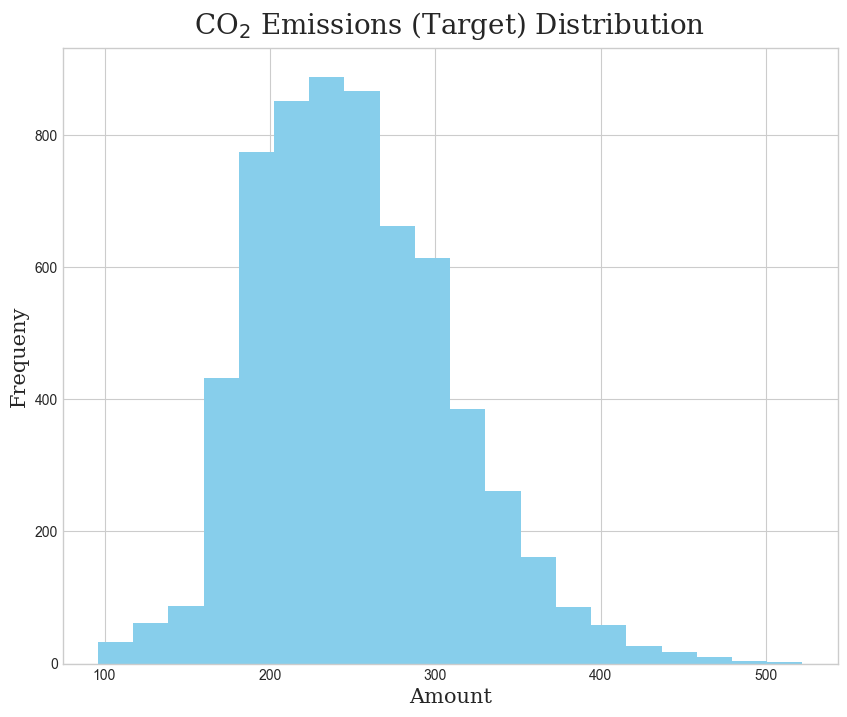

In [15]:
target.hist(bins=20, figsize=(10, 8), color='skyblue')
plt.title('CO$_2$ Emissions (Target) Distribution ', font='serif', pad=10, fontsize=20)
plt.ylabel('Frequeny', font='serif', fontsize=15)
plt.xlabel('Amount', font='serif', fontsize=15)
plt.show()

Text(0.5, 1.0, 'CO2 Emission Box Plot')

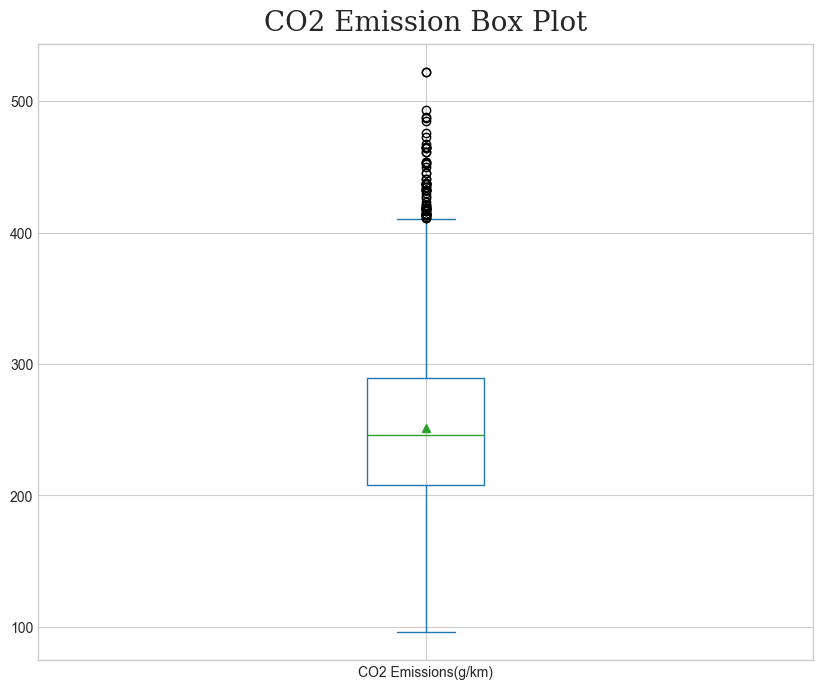

In [16]:
target.plot(kind='box', figsize=(10, 8), showmeans=True)
plt.title('CO2 Emission Box Plot', font='serif', fontsize=20, pad=10)

In [17]:
Q1 = np.quantile(target, 0.25)
Q2 = np.quantile(target, 0.5)
Q3 = np.quantile(target, 0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [18]:
outliers = target[(target < lower_bound) | (target > upper_bound)]

In [19]:
len(outliers)

74

## Numerical Features

In [20]:
numerical = df.drop(TARGET, axis=1).select_dtypes(include='number').columns.to_list()

In [21]:
numerical

['Engine Size(L)',
 'Cylinders',
 'Fuel Consumption City (L/100 km)',
 'Fuel Consumption Hwy (L/100 km)',
 'Fuel Consumption Comb (L/100 km)',
 'Fuel Consumption Comb (mpg)']

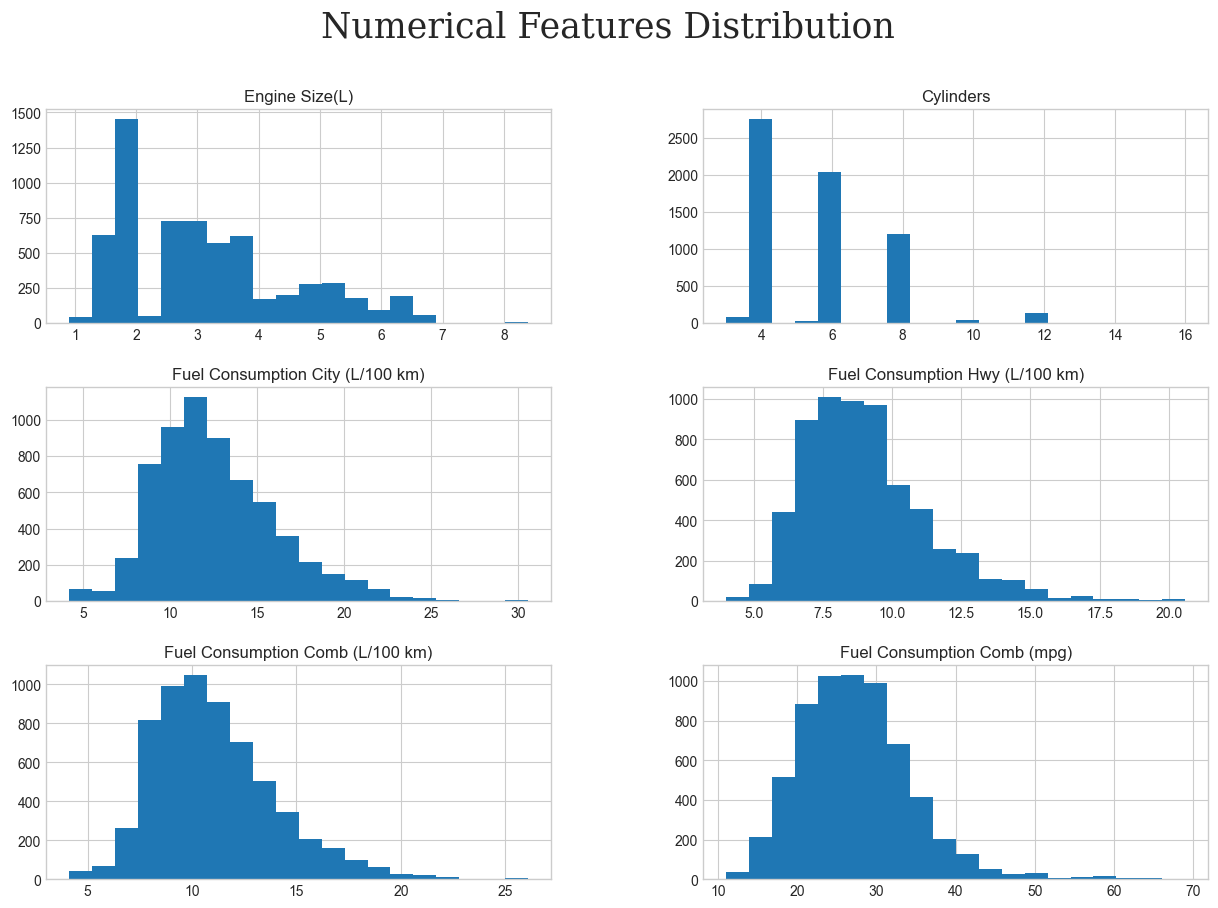

In [22]:
df[numerical].hist(bins=20, figsize=(15, 10))
plt.suptitle('Numerical Features Distribution', fontsize=25, font='serif')
plt.show()

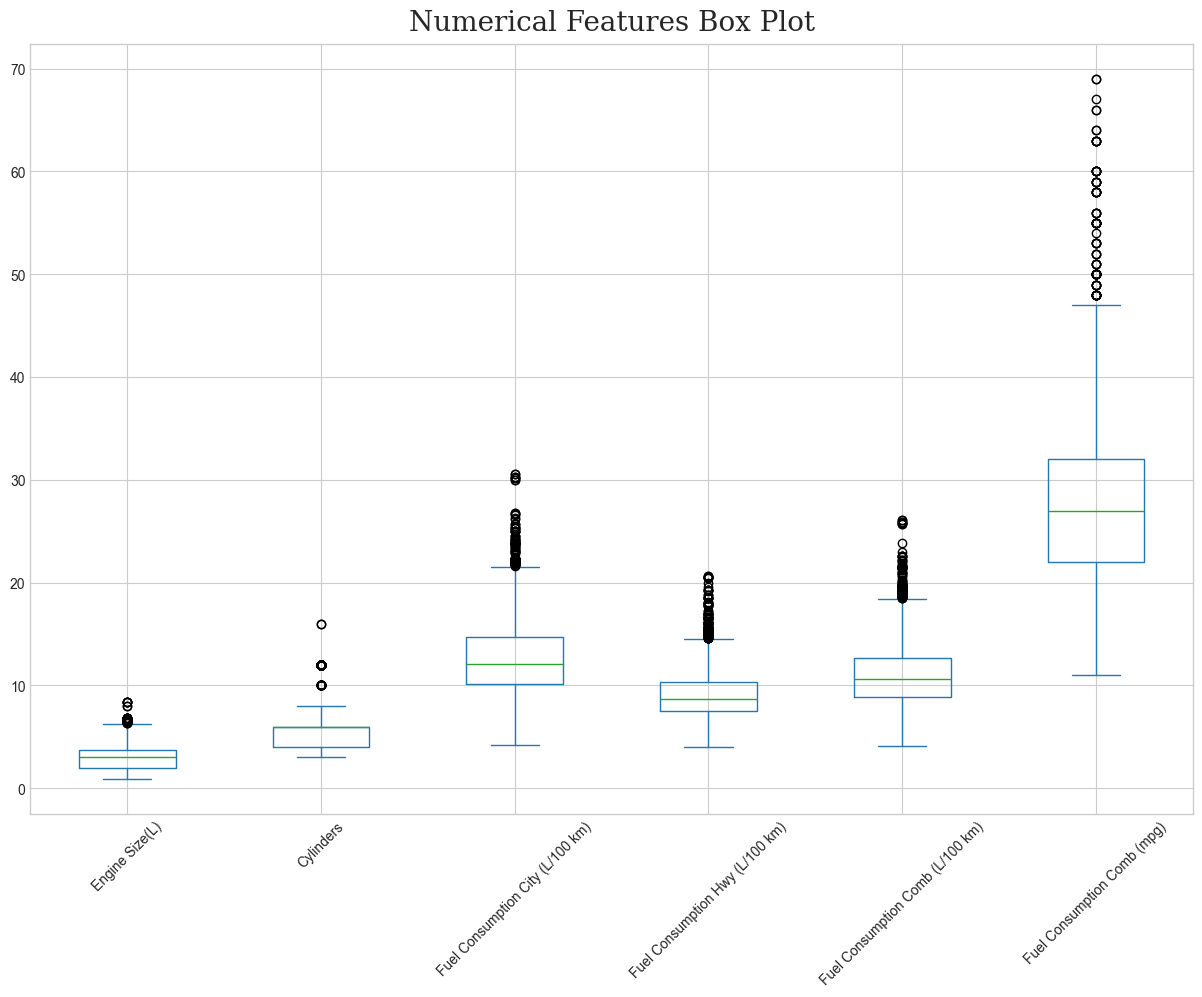

In [23]:
fig, ax = plt.subplots(figsize=(15, 10))
df[numerical].plot(kind='box', ax=ax)
ax.set_xticklabels(numerical, rotation=45)
ax.set_title('Numerical Features Box Plot', font='serif', fontsize=20, pad=10)
plt.show()

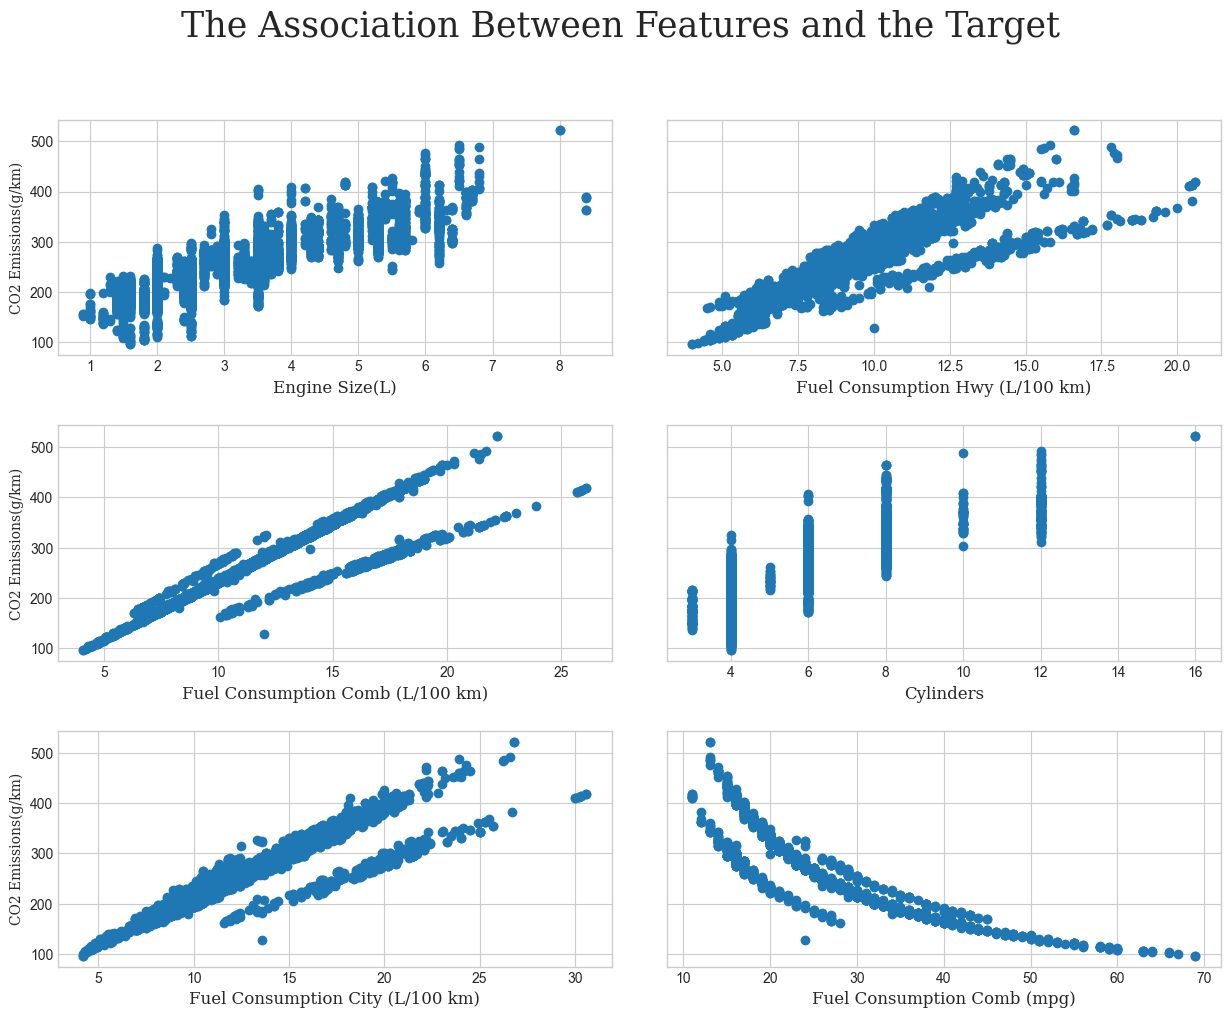

In [24]:
fig, ax = plt.subplots(3, 2, figsize=(15, 11), sharey=True)

for idx, col in enumerate(numerical):
    row = idx % 3
    column = idx % 2
    ax[row, column].scatter(df[col], df[TARGET])
    ax[row, column].set_xlabel(col, font='serif', fontsize=12)
    
for i in range(3):
    ax[i, 0].set_ylabel(TARGET, font='serif', fontsize=10)

plt.subplots_adjust(wspace=0.1, hspace=0.3)
plt.suptitle('The Association Between Features and the Target', font='serif', fontsize=25)
plt.show()

In [25]:
print('Outliers:')
for col_name in numerical:
    vals = df[col_name]
    Q1 = np.quantile(vals, 0.25)
    Q2 = np.quantile(vals, 0.5)
    Q3 = np.quantile(vals, 0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = vals[(vals < lower_bound) | (vals > upper_bound)]

    print('=' * 35)
    print(f'Column name: {col_name}, NO. outliers: {len(outliers)} \n')

Outliers:
Column name: Engine Size(L), NO. outliers: 121 

Column name: Cylinders, NO. outliers: 177 

Column name: Fuel Consumption City (L/100 km), NO. outliers: 116 

Column name: Fuel Consumption Hwy (L/100 km), NO. outliers: 150 

Column name: Fuel Consumption Comb (L/100 km), NO. outliers: 115 

Column name: Fuel Consumption Comb (mpg), NO. outliers: 95 



In [26]:
VIF = pd.DataFrame()
VIF['Features'] = numerical
VIF['VIF'] = [
    variance_inflation_factor(df[numerical], i)
    for i in range(len(numerical))
]

In [27]:
VIF

,Features,VIF
0,Engine Size(L),55.149606
1,Cylinders,78.945465
2,Fuel Consumption City (L/100 km),30259.576199
3,Fuel Consumption Hwy (L/100 km),10501.080825
4,Fuel Consumption Comb (L/100 km),75440.706943
5,Fuel Consumption Comb (mpg),6.885935


## Categorical Features

In [28]:
categorical = df.select_dtypes(include='object').columns.to_list()

In [29]:
categorical

['Make', 'Model', 'Vehicle Class', 'Transmission', 'Fuel Type']

In [30]:
for col in categorical:
    group = df.groupby(col)[TARGET].agg(['mean', 'std', 'min', 'max', 'count'])
    print('=' * 55)
    print(f'Column name: {col}')
    print(group)
    print()

Column name: Make
                     mean        std  min  max  count
Make                                                 
ACURA          221.666667  30.333260  136  267     51
ALFA ROMEO     231.315789  38.208569  193  292     19
ASTON MARTIN   344.282051  32.238379  264  450     39
AUDI           252.676806  46.657577  177  409    263
BENTLEY        367.914286  41.162784  291  465     35
BMW            252.514970  43.765720  181  370    501
BUGATTI        522.000000   0.000000  522  522      2
BUICK          233.750000  32.698968  182  323     92
CADILLAC       266.141844  41.409209  203  382    141
CHEVROLET      264.477670  65.726300  121  465    515
CHRYSLER       244.046875  27.643668  181  317     64
DODGE          277.088889  45.363866  168  387    180
FIAT           192.285714  16.301382  156  226     56
FORD           261.285962  55.114745  126  488    577
GENESIS        282.571429  26.734346  238  332     14
GMC            300.529412  49.724379  198  465    289
HONDA     

In [31]:
for col in categorical:
    group_mean = df.groupby(col)[TARGET].agg('mean')
    group_std = group_mean.std()
    print('=' * 35)
    print(f'Column name: {col}')
    print(group_std)
    print()

Column name: Make
69.99834185444743

Column name: Model
60.81726825405879

Column name: Vehicle Class
52.58631909405066

Column name: Transmission
45.62352872986599

Column name: Fuel Type
25.46707838109561



In [32]:
for col in categorical:
    groups = [
        group[TARGET]
        for _, group in df.groupby(col)
    ]
    f_stats, p_value = f_oneway(*groups)

    print('=' * 35)
    print(f'Column name: {col}')
    print(f'F-Stats: {round(f_stats, 2)}, P-Value: {round(p_value, 2)}')
    print()

Column name: Make
F-Stats: 89.83, P-Value: 0.0

Column name: Model
F-Stats: 46.26, P-Value: 0.0

Column name: Vehicle Class
F-Stats: 236.36, P-Value: 0.0

Column name: Transmission
F-Stats: 85.68, P-Value: 0.0

Column name: Fuel Type
F-Stats: 116.89, P-Value: 0.0



In [33]:
for col in categorical:
    encoder = OrdinalEncoder()

    x = encoder.fit_transform(df[[col]])

    mi = mutual_info_regression(
        x,
        df[TARGET],
        discrete_features=True
    )

    print('=' * 35)
    print(f'Column name: {col}')
    print(f'MI: {round(mi[0], 2)}')
    print()
    

Column name: Make
MI: 0.65

Column name: Model
MI: 1.86

Column name: Vehicle Class
MI: 0.45

Column name: Transmission
MI: 0.44

Column name: Fuel Type
MI: 0.11



In [34]:
len(df['Model'].unique())

2053

In [35]:
df['Model'].value_counts()

Model
F-150 FFV             32
F-150 FFV 4X4         31
MUSTANG               27
FOCUS FFV             24
F-150 4X4             20
                      ..
LS 500                 1
LS 500h                1
NX 300 AWD F SPORT     1
RX 350 L AWD           1
XC40 T4 AWD            1
Name: count, Length: 2053, dtype: int64

## Correlation Analysis

<Axes: >

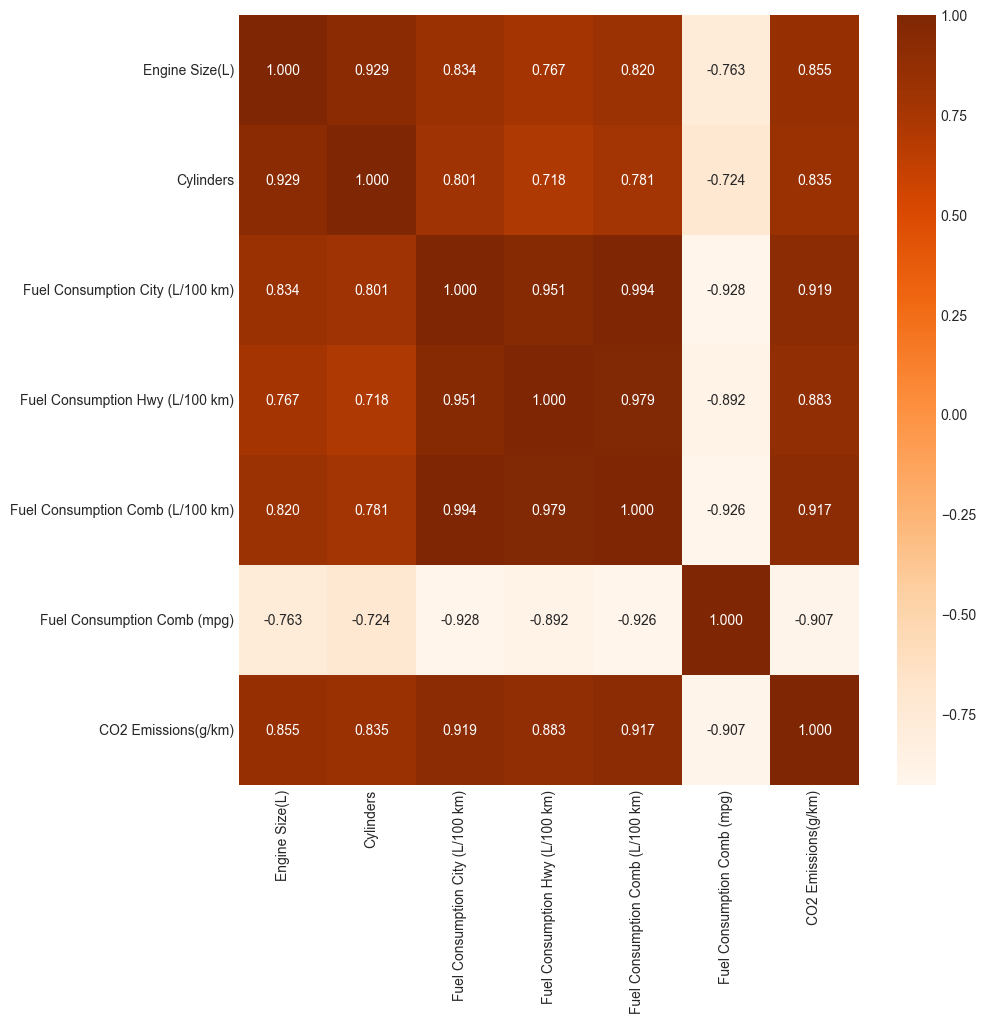

In [36]:
plt.figure(figsize=(10, 10))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.3f', cmap='Oranges')

<Axes: >

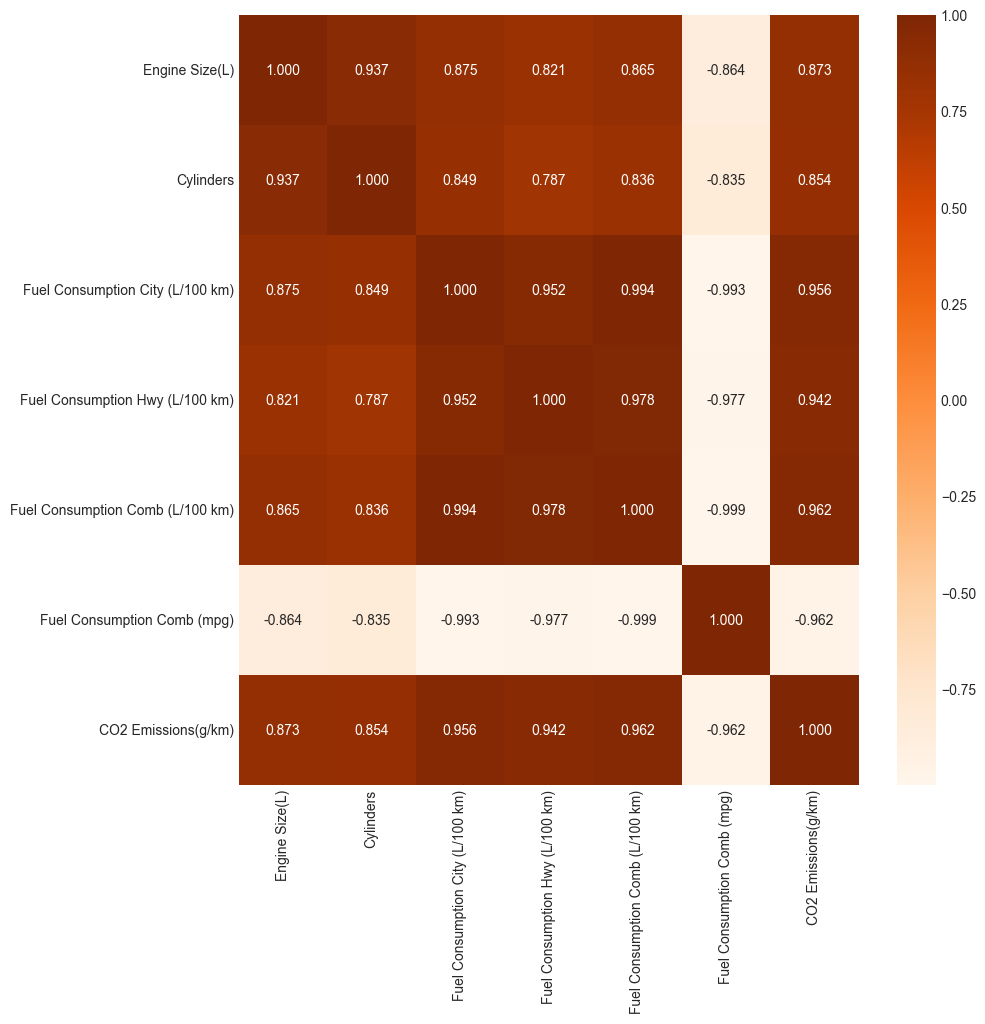

In [37]:
plt.figure(figsize=(10, 10))
corr_spearman = df.corr(numeric_only=True, method='spearman')
sns.heatmap(corr_spearman, annot=True, fmt='.3f', cmap='Oranges')

## Fuel Consumption Analysis

In [38]:
fuel_cols = [
    "Fuel Consumption City (L/100 km)",
    "Fuel Consumption Hwy (L/100 km)",
    "Fuel Consumption Comb (L/100 km)",
    "Fuel Consumption Comb (mpg)"
]

### Relationship with target

In [39]:
lin_corr = df[fuel_cols + [TARGET]].corr()[TARGET]

In [40]:
nonlin_corr = df[fuel_cols + [TARGET]].corr(method='spearman')[TARGET]

In [41]:
fuel_corr_comparison = pd.DataFrame(
    {
        'Pearson': lin_corr[:-1].values,
        'Spearman': nonlin_corr[:-1].values
    },
    index=lin_corr.index[:-1]
)

In [42]:
fuel_corr_comparison

,Pearson,Spearman
Fuel Consumption City (L/100 km),0.918756,0.956081
Fuel Consumption Hwy (L/100 km),0.883424,0.942182
Fuel Consumption Comb (L/100 km),0.916840,0.962399
Fuel Consumption Comb (mpg),-0.906783,-0.961680


### Redundancy Between Fuel Consumption Features

In [43]:
df[fuel_cols].corr()

,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg)
Fuel Consumption City (L/100 km),1.000000,0.950811,0.994052,-0.927640
Fuel Consumption Hwy (L/100 km),0.950811,1.000000,0.978607,-0.891892
Fuel Consumption Comb (L/100 km),0.994052,0.978607,1.000000,-0.925801
Fuel Consumption Comb (mpg),-0.927640,-0.891892,-0.925801,1.000000


In [44]:
df[fuel_cols].corr(method='spearman')

,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg)
Fuel Consumption City (L/100 km),1.000000,0.951612,0.994323,-0.993356
Fuel Consumption Hwy (L/100 km),0.951612,1.000000,0.978139,-0.977290
Fuel Consumption Comb (L/100 km),0.994323,0.978139,1.000000,-0.999010
Fuel Consumption Comb (mpg),-0.993356,-0.977290,-0.999010,1.000000


In [45]:
fuel_cons_mgp = 'Fuel Consumption Comb (mpg)'

df = df.drop(columns=fuel_cons_mgp)

In [46]:
df.columns

Index(['Make', 'Model', 'Vehicle Class', 'Engine Size(L)', 'Cylinders',
       'Transmission', 'Fuel Type', 'Fuel Consumption City (L/100 km)',
       'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)',
       'CO2 Emissions(g/km)'],
      dtype='object')

## Feature Selection Consideration

### High-cardinality Model

In [47]:
model_faeture_to_remove = 'Model'

In [48]:
df = df.drop(columns=model_faeture_to_remove)

In [49]:
df.columns

Index(['Make', 'Vehicle Class', 'Engine Size(L)', 'Cylinders', 'Transmission',
       'Fuel Type', 'Fuel Consumption City (L/100 km)',
       'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)',
       'CO2 Emissions(g/km)'],
      dtype='object')

### Inference-Time Feature Availability

|Features|Available at inference|Reason|
|:---:|:---:|:---:|
|Make|✓|Vehicle specification|
|Model|✓|Vehicle specification|
|Vehicle Class|✓|Vehicle specification|
|Engine Size|✓|Vehicle specification|
|Cylinders|✓|Vehicle specification|
|Fuel Type|✓|Vehicle specification|
|Transmission|✓|Vehicle specification|
|Vehicle Class|✓|Vehicle specification|
|Fuel Consumption City|✗|Requires vehicle testing|
|Fuel Consumption Hwy|✗|Requires vehicle testing|
|Fuel Consumption Comb|✗|Requires vehicle testing|

In [50]:
fuel_cols_to_reomve = [
    'Fuel Consumption City (L/100 km)',
    'Fuel Consumption Hwy (L/100 km)',
    'Fuel Consumption Comb (L/100 km)'
]

In [51]:
df = df.drop(columns=fuel_cols_to_reomve)

In [52]:
df.columns

Index(['Make', 'Vehicle Class', 'Engine Size(L)', 'Cylinders', 'Transmission',
       'Fuel Type', 'CO2 Emissions(g/km)'],
      dtype='object')

# Feature Engineering

In [53]:
numerical_features = df.drop(columns=TARGET).select_dtypes(include='number').columns.to_list()
categorical_features = df.select_dtypes(include='object').columns.to_list()

In [54]:
X_for_test = df.drop(columns=TARGET)
y_for_test = df[TARGET]

In [55]:
X_for_test_train, X_for_test_test, y_for_test_train, y_for_test_test = train_test_split(
    X_for_test,
    y_for_test,
    test_size=0.2,
    stratify=df['Make'],
    random_state=RANDOM_STATE
)

In [56]:
def add_cylinder_engine_ratio(X):
    if not isinstance(X, pd.DataFrame):
        raise TypeError('X must be a pandas DataFrame.')
    X = X.copy()
    X['Cylinder_pre_liter'] = X['numeric__Cylinders'] / X['numeric__Engine Size(L)']
    return X

def add_engine_cylinder_product(X):
    if not isinstance(X, pd.DataFrame):
        raise TypeError('X must be a pandas DataFrame.')
    X = X.copy()
    X['Engine_Cylinder_ratio'] = X['numeric__Engine Size(L)'] * X['numeric__Cylinders']
    return X

In [57]:
def build_test_preprocessor(*, numerical, categorical):
    preprocessor = ColumnTransformer(
        transformers=[
            (
                'ohe', 
                 OneHotEncoder(
                     handle_unknown='ignore',
                     sparse_output=False
                ), 
                categorical
            ),
            (
                'numeric',
                'passthrough',
                 numerical
            )
        ]
    )

    return preprocessor

In [58]:
model_for_test = XGBRegressor(random_state=RANDOM_STATE)

In [59]:
preprocessor = build_test_preprocessor(numerical=numerical_features,
                                      categorical=categorical_features)

In [60]:
test_pipeline1 = Pipeline(
    [
        ('preprocessor', preprocessor),
        ('scaler', StandardScaler()),
        ('model', model_for_test)
    ]
)


test_pipeline2 = Pipeline(
    [
        ('preprocessor', preprocessor),
        ('feature_set1', FunctionTransformer(add_cylinder_engine_ratio, validate=False)),
        ('scaler', StandardScaler()),
        ('model', model_for_test)
    ]
)

test_pipeline3 = Pipeline(
    [
        ('preprocessor', preprocessor),
        ('feature_set1', FunctionTransformer(add_cylinder_engine_ratio, validate=False)),
        ('feature_set2', FunctionTransformer(add_engine_cylinder_product, validate=False)),
        ('scaler', StandardScaler()),
        ('model', model_for_test)
    ]
)

test_pipelines = [
    test_pipeline1,
    test_pipeline2,
    test_pipeline3
]

names = [
    'Raw',
    '+ CYL / ENG',
    '+ CYL * ENG'
]

In [61]:
print('Result: ')
for name, pipeline in zip(names, test_pipelines):

    scores = -cross_val_score(
        pipeline,
        X_for_test_train,
        y_for_test_train,
        scoring='neg_root_mean_squared_error',
        cv=5,
        n_jobs=-1
    )

    result = {
        'Mean': scores.mean(),
        'STD': scores.std(),
        'Median': np.median(scores),
        'Min': scores.min(),
        'Max': scores.max()
    }
    print('=' * 35)
    print(f'Nmae: {name}')
    print(result)
    print()
    


Result: 
Nmae: Raw
{'Mean': 14.250390434265137, 'STD': 0.1609144645435749, 'Median': 14.294182777404785, 'Min': 13.9907865524292, 'Max': 14.422428131103516}

Nmae: + CYL / ENG
{'Mean': 14.110101890563964, 'STD': 0.3508684843295647, 'Median': 14.061493873596191, 'Min': 13.523261070251465, 'Max': 14.52289867401123}

Nmae: + CYL * ENG
{'Mean': 14.236027717590332, 'STD': 0.26707050279651673, 'Median': 14.32515811920166, 'Min': 13.806108474731445, 'Max': 14.527555465698242}



# Data Preprocessing

In [62]:
numerical_features = df.drop(columns=TARGET).select_dtypes(include='number').columns.to_list()
categorical_features = df.select_dtypes(include='object').columns.to_list()

In [63]:
numerical_features

['Engine Size(L)', 'Cylinders']

In [64]:
categorical_features

['Make', 'Vehicle Class', 'Transmission', 'Fuel Type']

In [65]:
X = df.drop(columns=TARGET)
y = df[TARGET]

In [66]:
X_train, x_test, y_train, y_test = train_test_split(
    X, 
    y,
    test_size=0.2,
    stratify=df['Make'],
    random_state=RANDOM_STATE
)

In [67]:
def build_features(X, prefix='numeric'):
    if not isinstance(X, pd.DataFrame):
        raise TypeError('X must be a pandas DataFrame.')
    X = X.copy()
    X['Cylinder_pre_liter'] = X[f'{prefix}__Cylinders'] / X[f'{prefix}__Engine Size(L)']
    return X

In [68]:
def build_preprocessor(*, numerical, categorical):
    cat_prefix = 'ohe'
    num_prefix = 'numeric'
    preprocessor = ColumnTransformer(
        transformers=[
            (
                cat_prefix,
                OneHotEncoder(handle_unknown='ignore', sparse_output=False),
                categorical
            ),
            (
                num_prefix,
                'passthrough',
                numerical
            )
        ]
    )

    return preprocessor

In [77]:
def build_pipeline(*, preprocessor, feature_builder, model):
    pipeline = Pipeline(
        [
            (
                'preprocess', 
                preprocessor
            ),
            (
                'feature_eng',
                FunctionTransformer(
                    feature_builder,
                    validate=False
                )
            ),
            (
                'sacler',
                StandardScaler()
            ),
            (
                'model',
                model
            )
        ]
    )

    return pipeline

In [78]:
preprocessor = build_preprocessor(categorical=categorical_features, numerical=numerical_features)

# Baseline Models

In [108]:
models = {
    "LR": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "Elastic": ElasticNet(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(random_state=42)
}

In [113]:
bl_cv_results = {}
n_cv = 10

In [114]:
for name, model in models.items():
    scores = -cross_val_score(
        build_pipeline(
            preprocessor=preprocessor,
            feature_builder=build_features,
            model=model
        ),
        X_train,
        y_train,
        scoring='neg_root_mean_squared_error',
        cv=n_cv
    )

    bl_cv_results[name] = scores

In [115]:
bl_res = pd.DataFrame(bl_cv_results).T

In [116]:
bl_res.columns = [f'Fold {i}' for i in range(1, n_cv + 1)]

In [117]:
bl_res

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Fold 6,Fold 7,Fold 8,Fold 9,Fold 10
LR,19.175415,21.803167,20.383047,18.381211,20.083033,21.294922,18.543941,19.608700,19.789497,21.122396
Ridge,19.174052,21.803055,20.382686,18.380555,20.083126,21.292756,18.543686,19.609477,19.788957,21.123630
Lasso,21.121964,23.314704,22.154590,19.450366,22.049927,22.471837,20.720788,22.116493,21.118404,23.731289
Elastic,22.023798,25.514774,24.383153,21.333484,24.043168,24.210020,22.490722,24.319675,22.984738,26.181460
Decision Tree,13.348427,12.970972,14.481047,13.740518,16.050360,14.297764,13.769311,14.249499,13.757534,14.921539
Random Forest,13.136881,12.882318,13.307938,13.381293,14.337811,14.399766,13.054617,14.052124,13.300051,14.840473
XGBoost,13.302887,13.019980,13.742479,13.584792,13.777048,14.768962,12.495567,14.152821,12.897733,14.727719
Extra Trees,13.457276,12.548097,13.629309,13.554536,14.146076,14.436736,13.191523,13.943363,13.020201,15.016749


# Baseline Model Comparison

In [118]:
print('Baseline results conclusion: ')
for name, scores in bl_cv_results.items():
    mean = scores.mean()
    std = scores.std()
    mdian = np.median(scores)
    minimum = scores.min()
    maximum = scores.max()
    print('=' * 60)
    print(f'Name: {name}')
    print(f'Mean: {mean:.2f}, SD: {std:.2f}, Mdian: {mdian:.2f}, Min: {minimum:.2f}, Max: {maximum:.2f}')
    print()

Baseline results conclusion: 
Name: LR
Mean: 20.02, SD: 1.09, Mdian: 19.94, Min: 18.38, Max: 21.80

Name: Ridge
Mean: 20.02, SD: 1.09, Mdian: 19.94, Min: 18.38, Max: 21.80

Name: Lasso
Mean: 21.83, SD: 1.20, Mdian: 22.08, Min: 19.45, Max: 23.73

Name: Elastic
Mean: 23.75, SD: 1.45, Mdian: 24.13, Min: 21.33, Max: 26.18

Name: Decision Tree
Mean: 14.16, SD: 0.83, Mdian: 14.01, Min: 12.97, Max: 16.05

Name: Random Forest
Mean: 13.67, SD: 0.64, Mdian: 13.34, Min: 12.88, Max: 14.84

Name: XGBoost
Mean: 13.65, SD: 0.71, Mdian: 13.66, Min: 12.50, Max: 14.77

Name: Extra Trees
Mean: 13.69, SD: 0.68, Mdian: 13.59, Min: 12.55, Max: 15.02



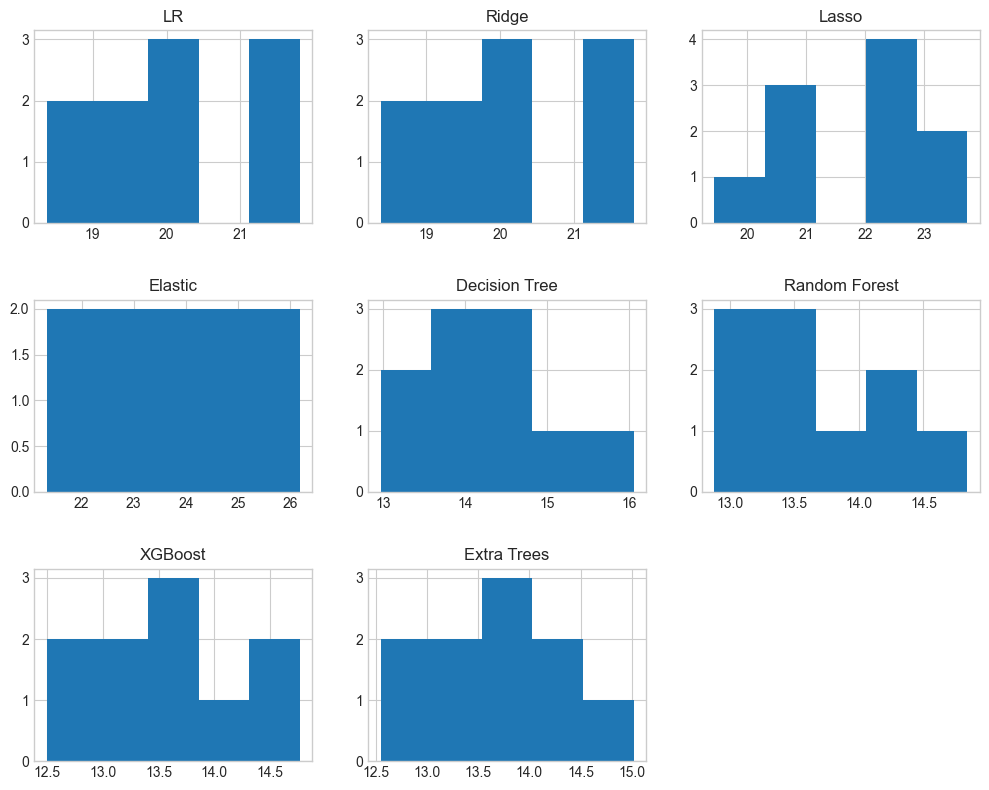

In [124]:
bl_res.T.hist(bins=5, figsize=(10, 8))
plt.tight_layout()
plt.subplots_adjust(hspace=0.4, wspace=0.2)
plt.show()

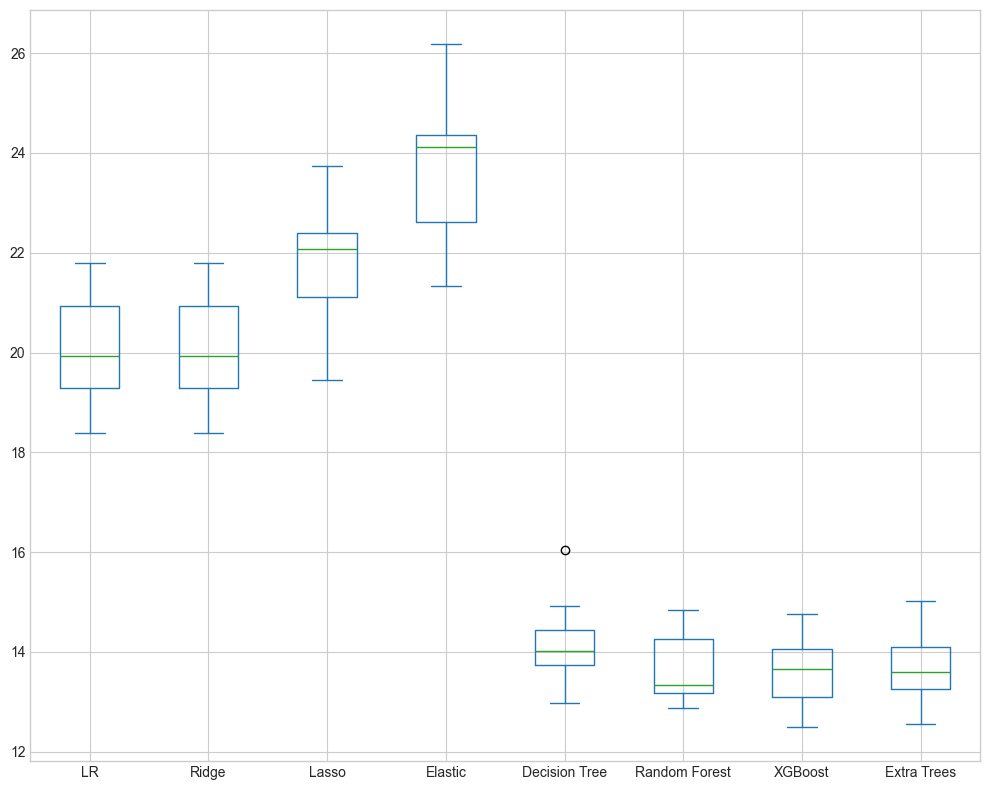

In [127]:
bl_res.T.plot(kind='box', figsize=(10, 8))
plt.tight_layout()
plt.show()

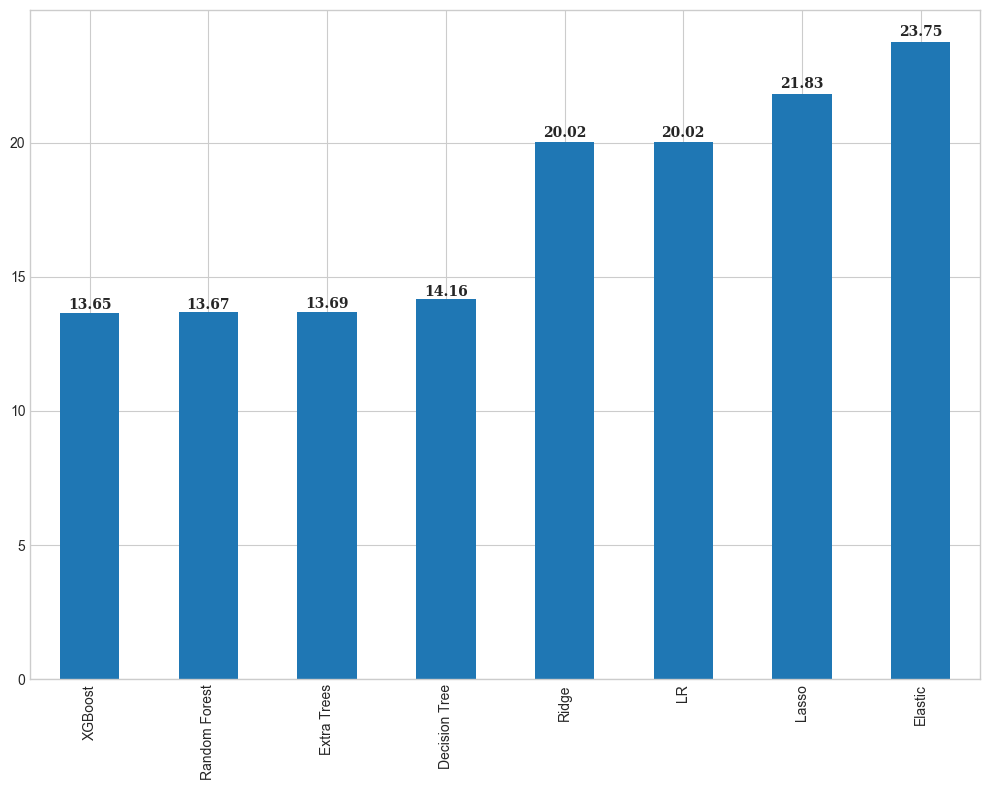

In [179]:
means = bl_res.T.mean().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 8))
means.plot(kind='bar', ax=ax)
for idx, mean in enumerate(means):
    ax.text(
        idx, 
        mean * 1.01, 
        f'{mean:.2f}',
        font='serif',
        weight='bold',
        ha='center'
    )
plt.tight_layout()
plt.show()

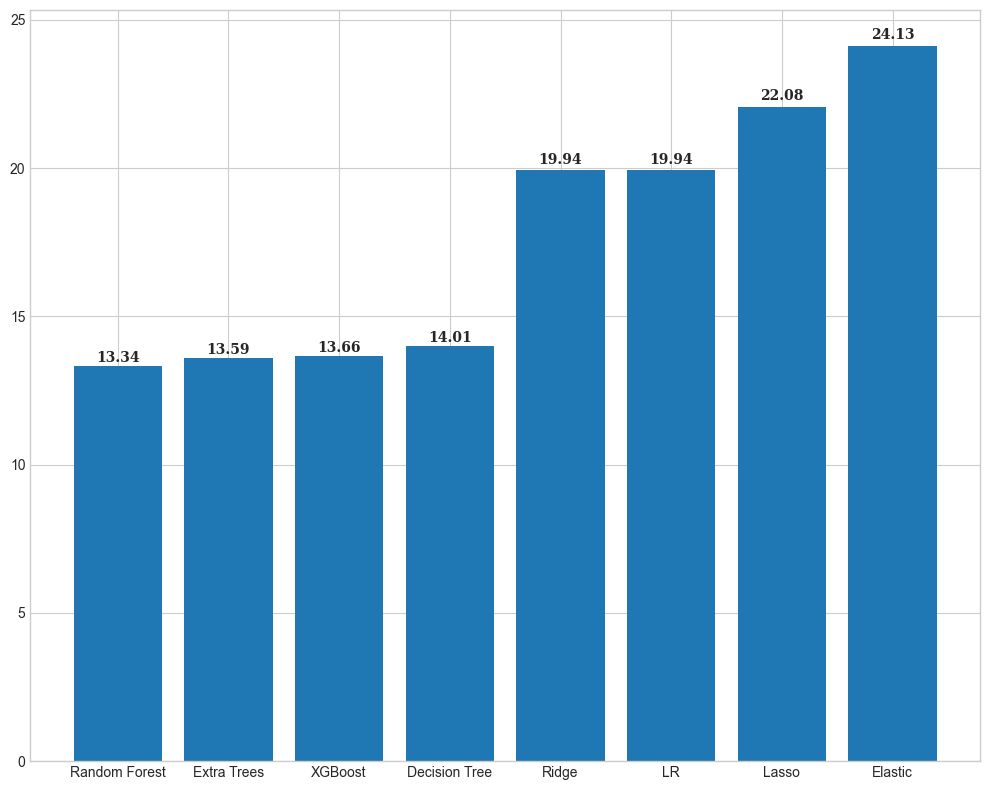

In [180]:
medians = {name: np.median(vals) for name, vals in bl_cv_results.items()}
medians = sorted(
    medians.items(),
    key=lambda item: item[1]              
)
medians = {name: round(val, 2) for name, val in medians}


fig, ax = plt.subplots(figsize=(10, 8))
ax.bar(medians.keys(), medians.values())

for idx, val in enumerate(medians.values()):
    ax.text(
        idx,
        val * 1.01,
        val,
        font='serif',
        weight='bold',
        ha='center'
    )    

plt.tight_layout()
plt.show()

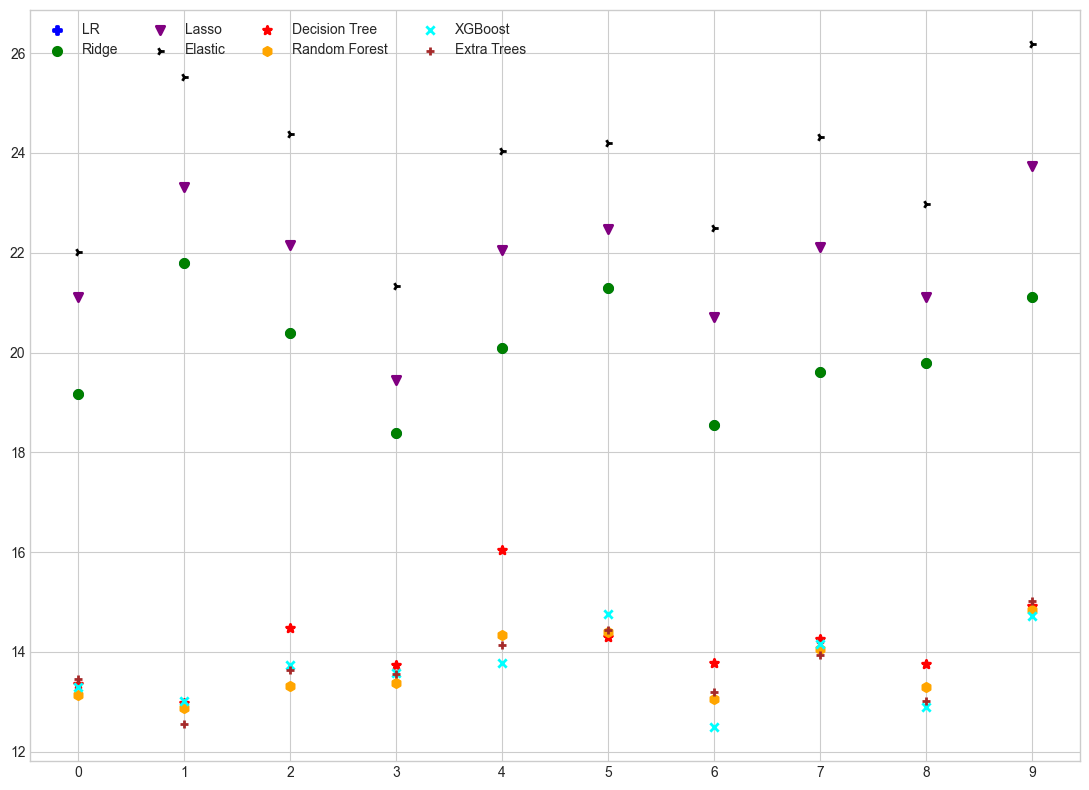

In [188]:
fig, ax = plt.subplots(figsize=(11, 8))
markers = ['P', 'o', 'v', '4', '*', 'h', 'x', '+']
colors = ['blue', 'green', 'purple', 'black', 'red', 'orange', 'cyan', 'brown']

for (name, values), marker, color in zip(bl_cv_results.items(), markers, colors):
    ax.scatter(
        range(n_cv),
        values,
        marker=marker,
        color=color,
        label=name,
        lw=2
    )
ax.set_xticks(range(n_cv))
ax.legend(ncols=len(bl_cv_results) / 2)
plt.tight_layout()
plt.show()

# Hyperparameter Optimization

In [189]:
cv = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

## Random Forest

## XGB

## Extra Trees

## Decision Tree

# Optimized Model Evaluation

# Model Diagnostics

# Final Model Selection

# Final Evaluation & Interpretation   

# Conclusions & Limitations